In [1]:
import sklearn
import pandas as pd
import numpy as np
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_svmlight_file

In [2]:
%run ./preprocess.py

In [2]:
import numpy as np
data=np.load("processed_housing.npz")
X_train_final = data["X_train"].astype(np.float64)
X_test_final = data["X_test"].astype(np.float64)
y_train = data["y_train"].astype(np.float64).ravel()
y_test = data["y_test"].astype(np.float64).ravel()

In [3]:
def mse_loss(y_true,y_pred):
    y_true=np.asarray(y_true)
    y_pred=np.asarray(y_pred)

    return np.mean((y_true-y_pred)**2)

In [7]:
import numpy as np

X_train_bias=np.c_[np.ones((X_train_final.shape[0],1))
    ,X_train_final]

X_test_bias=np.c_[np.ones((X_test_final.shape[0],1))
,X_test_final]

XTX = np.dot(X_train_bias.T, X_train_bias)
XTy = np.dot(X_train_bias.T, y_train)

theta = np.linalg.solve(XTX, XTy)

y_train_pred = np.dot(X_train_bias, theta)
y_test_pred = np.dot(X_test_bias, theta)

train_mse=mse_loss(y_train,y_train_pred)
test_mse=mse_loss(y_test,y_test_pred)
print("train_mse =", train_mse)
print("test_mse =", test_mse)

train_mse = 21.355352259156238
test_mse = 24.229300089847


In [8]:
import numpy as np
X_train_bias=np.c_[np.ones((X_train_final.shape[0],1)),
    X_train_final]

y_train_col=y_train.reshape(-1,1)

W=np.linalg.pinv(
    X_train_bias.T @ X_train_bias
)@ X_train_bias.T @ y_train_col

/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/var/folders/tl/wp7xpxwn7k76pxv4vxnwk40w0000gn/T/ipykernel_2530/3145678812.py:7: RuntimeWarning: divide by zero encountered in matmul
  W=np.linalg.pinv(
/var/folders/tl/wp7xpxwn7k76pxv4vxnwk40w0000gn/T/ipykernel_2530/3145678812.py:7: RuntimeWarning: overflow encountered in matmul
  W=np.linalg.pinv(
/var/folders/tl/wp7xpxwn

In [9]:
import numpy as np

X_train_bias = np.c_[
    np.ones((X_train_final.shape[0],1)),
    X_train_final
]

X_val_bias = np.c_[
    np.ones((X_test_final.shape[0],1)),
    X_test_final
]

W=np.linalg.pinv(X_train_bias)@ y_train.reshape(-1,1)

y_train_pred=(X_train_bias @ W).ravel()

y_val_pred=(X_val_bias@W).ravel()

loss_train=np.mean((y_train-y_train_pred)**2)
loss_val=np.mean((y_test-y_val_pred)**2)

print("loss_train=",loss_train)
print("loss_test=",loss_val)

loss_train= 21.355352259156245
loss_test= 24.229300089846912


/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/var/folders/tl/wp7xpxwn7k76pxv4vxnwk40w0000gn/T/ipykernel_2530/720172584.py:13: RuntimeWarning: divide by zero encountered in matmul
  W=np.linalg.pinv(X_train_bias)@ y_train.reshape(-1,1)
/var/folders/tl/wp7xpxwn7k76pxv4vxnwk40w0000gn/T/ipykernel_2530/720172584.py:13: RuntimeWarning: overflow encountered in matmul
  W=np.l

['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'CRIMlog', 'ZNlog', 'RADlog']
RM index: 5
(404,)
(102,)
w = 3.4777996307076107
b = 19.72211126882061
loss_train = 84.10000373269177
loss_val = 68.29303194775109


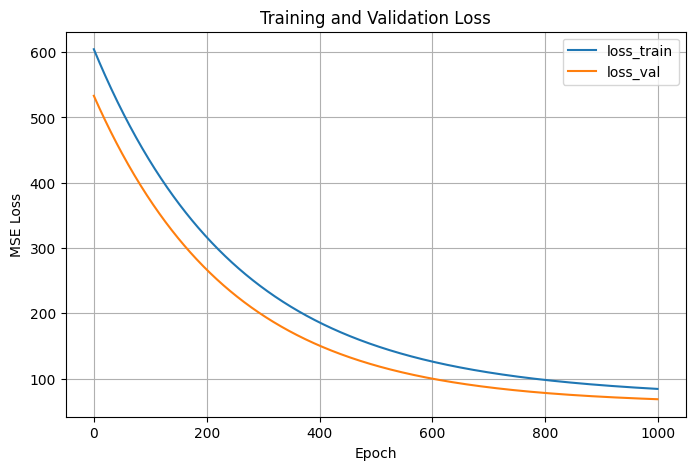

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import joblib

data = np.load("processed_housing.npz")
info = joblib.load("preprocess_objects.joblib")
feature_names=info["feature_names"]
print(feature_names)

#find rm
rm_index = feature_names.index("RM")
print("RM index:",rm_index)

X_train_rm=data["X_train"][:,rm_index].astype(np.float64)
X_val_rm=data["X_test"][:,rm_index].astype(np.float64)
y_train=data["y_train"].astype(np.float64)
y_val=data["y_test"].astype(np.float64)
print(X_train_rm.shape)
print(X_val_rm.shape)

#define function
def mse_loss(y_true,y_pred):
    return ((y_true-y_pred)**2).mean()

# reason gradient
def compute_gradients(x,y,w,b):
    y_pred=w*x+b
    error=y_pred-y

    dw=2*np.mean(error*x)
    db=2*np.mean(error)

    return dw,db


alpha=0.001
epochs=1000

w=0.0
b=0.0

loss_train_history=[]
loss_val_history=[]

for epoch in range(epochs):
    dw,db=compute_gradients(
        X_train_rm,
        y_train,
        w,
        b
    )

    w=w-alpha*dw
    b=b-alpha*db

    y_train_pred=w*X_train_rm+b
    y_val_pred=w*X_val_rm+b

    loss_train=mse_loss(y_train,y_train_pred)
    loss_val=mse_loss(y_val,y_val_pred)
    loss_train_history.append(loss_train)
    loss_val_history.append(loss_val)

print("w =", w)
print("b =", b)
print("loss_train =", loss_train_history[-1])
print("loss_val =", loss_val_history[-1])


plt.figure(figsize=(8, 5))

plt.plot(
    range(epochs),
    loss_train_history,
    label="loss_train"
)

plt.plot(
    range(epochs),
    loss_val_history,
    label="loss_val"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

multi_model=LinearRegression()

multi_model.fit(X_train_final,y_train)

y_train_pred_multi=multi_model.predict(X_train_final)
y_val_pred_multi=multi_model.predict(X_test_final)

loss_train_multi=mean_squared_error(y_train,y_train_pred_multi)
loss_val_multi=mean_squared_error(y_test,y_val_pred_multi)
print("多变量训练集 MSE =", loss_train_multi)
print("多变量验证集 MSE =", loss_val_multi)

y_train_pred_single=w*X_train_rm+b
y_val_pred_single=w*X_val_rm+b

loss_train_single=mean_squared_error(y_train,y_train_pred_single)
loss_val_single=mean_squared_error(y_test,y_val_pred_single)
print("单变量训练集 MSE =", loss_train_single)
print("单变量验证集 MSE =", loss_val_single)
print("\n模型对比：")
print("单变量训练集 MSE：", loss_train_single)
print("多变量训练集 MSE：", loss_train_multi)
print("单变量验证集 MSE：", loss_val_single)
print("多变量验证集 MSE：", loss_val_multi)

多变量训练集 MSE = 21.355352259156245
多变量验证集 MSE = 24.229300089846912
单变量训练集 MSE = 44.58209512768721
单变量验证集 MSE = 45.44407892806142

模型对比：
单变量训练集 MSE： 44.58209512768721
多变量训练集 MSE： 21.355352259156245
单变量验证集 MSE： 45.44407892806142
多变量验证集 MSE： 24.229300089846912


/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/leo/Desktop/experiment1-house pricing/machine-learning-class-experiment1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/leo/Desktop/experiment1-house pricing/machin